# 🩺 Multi-Task ResNet-50: Neonatal Jaundice Screening

**Input**: Pixel values from neonatal skin images (RGB + HSV branches)  
**Targets** (from CSV):
- `blood(mg/dL)` → Regression (predict exact bilirubin level)
- `Treatment` → Classification (0 = no treatment, 1 = needs phototherapy)

**CSV column `image_idx`** contains the filename (e.g. `0003-1.jpg`) that maps directly to the `images/` folder.

## Cell 1: Imports & Hardcoded Constants

In [9]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, applications
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
from sklearn.preprocessing import MinMaxScaler

# ──────────────────────────────────────────────
# HARDCODED PATHS – Change these if your folders move
# ──────────────────────────────────────────────
CSV_PATH  = '/Users/shubhbhateja/College/minor_project/NeoJaundice/chd_jaundice_published_2.csv'
IMAGE_DIR = '/Users/shubhbhateja/College/minor_project/images'

# ──────────────────────────────────────────────
# HARDCODED MODEL SETTINGS
# ──────────────────────────────────────────────
IMG_W, IMG_H = 128, 128          # Pixel dimensions fed to ResNet
INPUT_SHAPE  = (IMG_W, IMG_H, 3) # 3 channels (RGB or HSV)
BATCH_SIZE   = 16
EPOCHS       = 50
LR           = 1e-4              # Small learning rate for fine-tuning

print("All imports loaded. Constants set.")

All imports loaded. Constants set.


## Cell 2: Load CSV & Verify Columns
We confirm that `image_idx` maps directly to filenames in the `images/` folder, and inspect both targets.

In [10]:
df = pd.read_csv(CSV_PATH)

print(f"CSV has {len(df)} rows and columns: {list(df.columns)}")
print(f"\nSample rows:")
display(df[['image_idx', 'blood(mg/dL)', 'Treatment']].head(8))

# Verify image files actually exist for the first few rows
for name in df['image_idx'].head(3):
    full_path = os.path.join(IMAGE_DIR, name)
    exists = os.path.isfile(full_path)
    print(f"  {name} -> exists: {exists}")

print(f"\n── Target 1: blood(mg/dL) (Regression) ──")
print(f"  Min: {df['blood(mg/dL)'].min()}, Max: {df['blood(mg/dL)'].max()}, Mean: {df['blood(mg/dL)'].mean():.2f}")

print(f"\n── Target 2: Treatment (Classification) ──")
print(f"  0 (no treatment): {(df['Treatment']==0).sum()}")
print(f"  1 (needs treatment): {(df['Treatment']==1).sum()}")

CSV has 2235 rows and columns: ['patient_id', 'image_idx', 'gender', 'gestational_age', 'age(day)', 'weight', 'blood(mg/dL)', 'Treatment']

Sample rows:


,image_idx,blood(mg/dL),Treatment
0,0003-1.jpg,3.9,0
1,0003-2.jpg,3.9,0
2,0003-3.jpg,3.9,0
3,0035-1.jpg,12.2,0
4,0035-2.jpg,12.2,0
5,0035-3.jpg,12.2,0
6,0002-1.jpg,11.9,0
7,0002-2.jpg,11.9,0


  0003-1.jpg -> exists: True
  0003-2.jpg -> exists: True
  0003-3.jpg -> exists: True

── Target 1: blood(mg/dL) (Regression) ──
  Min: 0.0, Max: 25.7, Mean: 11.21

── Target 2: Treatment (Classification) ──
  0 (no treatment): 1302
  1 (needs treatment): 933


## Cell 3: Visual Preprocessing Audit
Run this on any image to see EXACTLY what the model receives.  
Change `SAMPLE_ROW` to inspect different patients.

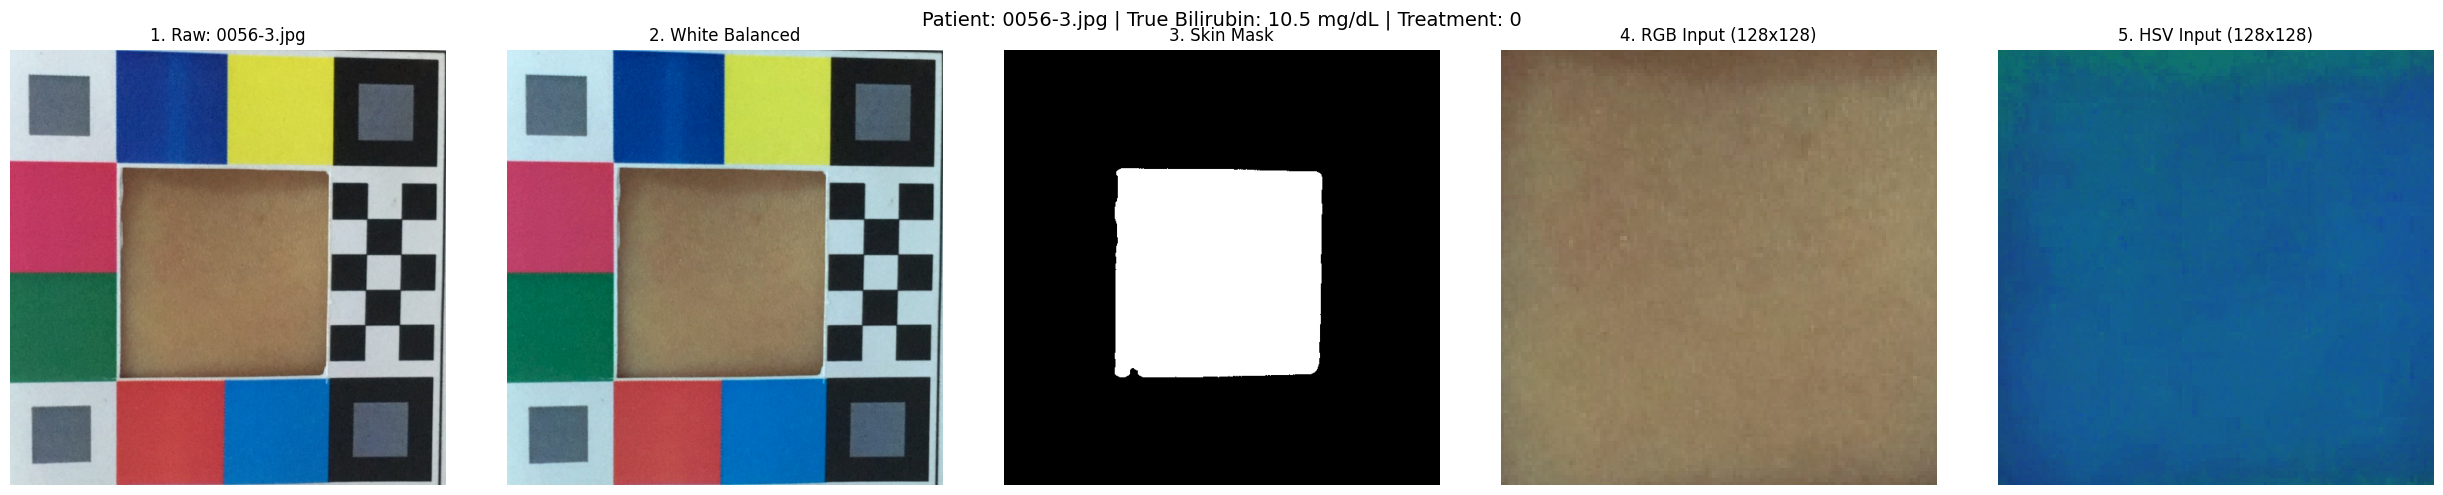

In [11]:
SAMPLE_ROW = 50  # <-- Change this number to inspect different images

def white_balance(bgr_img):
    """Gray World white balance in LAB space."""
    lab = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2LAB)
    avg_a = np.average(lab[:, :, 1])
    avg_b = np.average(lab[:, :, 2])
    lab[:, :, 1] = lab[:, :, 1] - ((avg_a - 128) * (lab[:, :, 0] / 255.0) * 1.1)
    lab[:, :, 2] = lab[:, :, 2] - ((avg_b - 128) * (lab[:, :, 0] / 255.0) * 1.1)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

def crop_skin(rgb_img):
    """YCrCb skin thresholding + largest contour crop."""
    h, w = rgb_img.shape[:2]
    ycrcb = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2YCrCb)
    mask = cv2.inRange(ycrcb, np.array([0, 133, 77]), np.array([255, 173, 127]))
    mask[int(h * 0.85):, :] = 0  # Ignore bottom 15% (color card)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=2)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        x, y, wb, hb = cv2.boundingRect(max(contours, key=cv2.contourArea))
        ix, iy = int(wb * 0.05), int(hb * 0.05)
        return rgb_img[y+iy:y+hb-iy, x+ix:x+wb-ix], mask
    return rgb_img, mask

# ── Run the pipeline on one image ──
row = df.iloc[SAMPLE_ROW]
img_name = row['image_idx']
true_bili = row['blood(mg/dL)']
true_treat = row['Treatment']

raw_bgr = cv2.imread(os.path.join(IMAGE_DIR, img_name))
raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)

balanced_bgr = white_balance(raw_bgr)
balanced_rgb = cv2.cvtColor(balanced_bgr, cv2.COLOR_BGR2RGB)

skin_patch, skin_mask = crop_skin(balanced_rgb)

final_rgb = cv2.resize(skin_patch, (IMG_W, IMG_H))
final_hsv = cv2.cvtColor(final_rgb, cv2.COLOR_RGB2HSV)

# ── Plot ──
fig, axes = plt.subplots(1, 5, figsize=(25, 5))
axes[0].imshow(raw_rgb);       axes[0].set_title(f"1. Raw: {img_name}")
axes[1].imshow(balanced_rgb);  axes[1].set_title("2. White Balanced")
axes[2].imshow(skin_mask, cmap='gray'); axes[2].set_title("3. Skin Mask")
axes[3].imshow(final_rgb);     axes[3].set_title(f"4. RGB Input ({IMG_W}x{IMG_H})")
axes[4].imshow(final_hsv);     axes[4].set_title(f"5. HSV Input ({IMG_W}x{IMG_H})")
for ax in axes: ax.axis('off')
plt.suptitle(f"Patient: {img_name} | True Bilirubin: {true_bili} mg/dL | Treatment: {true_treat}", fontsize=14)
plt.tight_layout()
plt.show()

## Cell 4: Process All Images Into Arrays
For each row in the CSV:
- `image_idx` → load image → white balance → crop skin → resize to 128×128
- Extract `blood(mg/dL)` as **regression target**
- Extract `Treatment` as **classification target**

In [12]:
def process_one_image(img_path):
    """Full pipeline: load → white balance → skin crop → resize → normalize pixels to [0,1]."""
    bgr = cv2.imread(img_path)
    if bgr is None:
        return None, None

    # Step 1: White balance
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    avg_a, avg_b = np.average(lab[:, :, 1]), np.average(lab[:, :, 2])
    lab[:, :, 1] = lab[:, :, 1] - ((avg_a - 128) * (lab[:, :, 0] / 255.0) * 1.1)
    lab[:, :, 2] = lab[:, :, 2] - ((avg_b - 128) * (lab[:, :, 0] / 255.0) * 1.1)
    rgb = cv2.cvtColor(cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), cv2.COLOR_BGR2RGB)

    # Step 2: Skin crop
    h, w = rgb.shape[:2]
    ycrcb = cv2.cvtColor(rgb, cv2.COLOR_RGB2YCrCb)
    mask = cv2.inRange(ycrcb, np.array([0, 133, 77]), np.array([255, 173, 127]))
    mask[int(h * 0.85):, :] = 0
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,
                            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)), iterations=2)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        x, y, wb, hb = cv2.boundingRect(max(contours, key=cv2.contourArea))
        ix, iy = int(wb * 0.05), int(hb * 0.05)
        skin = rgb[y+iy:y+hb-iy, x+ix:x+wb-ix]
    else:
        skin = rgb

    # Step 3: Resize + normalize pixels to [0, 1]
    final_rgb = cv2.resize(skin, (IMG_W, IMG_H)).astype(np.float32) / 255.0
    final_hsv = cv2.cvtColor((final_rgb * 255).astype(np.uint8), cv2.COLOR_RGB2HSV).astype(np.float32) / 255.0

    return final_rgb, final_hsv

# ── Process every row ──
X_rgb_list, X_hsv_list = [], []
Y_bili_list, Y_treat_list = [], []

print("Processing all images...")
for idx, row in df.iterrows():
    img_path = os.path.join(IMAGE_DIR, row['image_idx'])   # image_idx = filename
    rgb_tensor, hsv_tensor = process_one_image(img_path)
    if rgb_tensor is not None:
        X_rgb_list.append(rgb_tensor)
        X_hsv_list.append(hsv_tensor)
        Y_bili_list.append(row['blood(mg/dL)'])   # Target 1: exact number
        Y_treat_list.append(row['Treatment'])      # Target 2: 0 or 1
    if idx % 500 == 0:
        print(f"  ...processed {idx}/{len(df)}")

X_rgb   = np.array(X_rgb_list)
X_hsv   = np.array(X_hsv_list)
Y_bili  = np.array(Y_bili_list, dtype=np.float32)
Y_treat = np.array(Y_treat_list, dtype=np.float32)

print(f"\nDone! {len(X_rgb)} valid images processed.")
print(f"X_rgb shape: {X_rgb.shape}  (pixels are normalized 0-1)")
print(f"Y_bili range: {Y_bili.min():.1f} – {Y_bili.max():.1f} mg/dL")
print(f"Y_treat distribution: 0→{(Y_treat==0).sum()}, 1→{(Y_treat==1).sum()}")

Processing all images...
  ...processed 0/2235
  ...processed 500/2235
  ...processed 1000/2235
  ...processed 1500/2235
  ...processed 2000/2235

Done! 2235 valid images processed.
X_rgb shape: (2235, 128, 128, 3)  (pixels are normalized 0-1)
Y_bili range: 0.0 – 25.7 mg/dL
Y_treat distribution: 0→1302, 1→933


## Cell 5: Scale Bilirubin Target & Split Data
**Why scale?** Neural networks work best when targets are small decimals.  
We use `MinMaxScaler` to map `blood(mg/dL)` from `[0, 25.7]` → `[0, 1]`.  
At inference time, we reverse this to get real mg/dL numbers back.

In [13]:
# ── Scale bilirubin to [0, 1] ──
bili_scaler = MinMaxScaler()
Y_bili_scaled = bili_scaler.fit_transform(Y_bili.reshape(-1, 1)).flatten()

print(f"Before scaling: min={Y_bili.min():.1f}, max={Y_bili.max():.1f}")
print(f"After scaling:  min={Y_bili_scaled.min():.3f}, max={Y_bili_scaled.max():.3f}")

# ── 70 / 10 / 20 Split ──
# Step 1: Carve out 20% test
X_rgb_tmp, X_rgb_test, X_hsv_tmp, X_hsv_test, \
yt_tmp, yt_test, yb_tmp, yb_test = train_test_split(
    X_rgb, X_hsv, Y_treat, Y_bili_scaled,
    test_size=0.20, random_state=42, stratify=Y_treat
)

# Step 2: From the remaining 80%, carve 10% for validation (10/80 = 0.125)
X_rgb_train, X_rgb_val, X_hsv_train, X_hsv_val, \
yt_train, yt_val, yb_train, yb_val = train_test_split(
    X_rgb_tmp, X_hsv_tmp, yt_tmp, yb_tmp,
    test_size=0.125, random_state=42, stratify=yt_tmp
)

print(f"\nTRAIN: {len(X_rgb_train)} ({len(X_rgb_train)/len(X_rgb)*100:.0f}%)")
print(f"VAL:   {len(X_rgb_val)} ({len(X_rgb_val)/len(X_rgb)*100:.0f}%)")
print(f"TEST:  {len(X_rgb_test)} ({len(X_rgb_test)/len(X_rgb)*100:.0f}%)")

# ── Class weights for classification balance ──
cw = class_weight.compute_class_weight('balanced', classes=np.array([0,1]), y=yt_train.astype(int))
class_wt = {0: cw[0], 1: cw[1]}
print(f"\nClass weights: {class_wt}")

Before scaling: min=0.0, max=25.7
After scaling:  min=0.000, max=1.000

TRAIN: 1564 (70%)
VAL:   224 (10%)
TEST:  447 (20%)

Class weights: {0: np.float64(0.858397365532382), 1: np.float64(1.1975497702909648)}


## Cell 6: Build the Multi-Task Model
Two separate output heads branch from the shared ResNet-50 features:
- **Treatment head**: sigmoid → binary crossentropy (classification)
- **Bilirubin head**: linear → MAE (regression)

`loss_weights=[1.0, 5.0]`: We boost the regression loss 5× so the optimizer 
cannot ignore it in favor of the easier classification task.

In [14]:
def build_model():
    # ── INPUTS ──
    inp_rgb = layers.Input(shape=INPUT_SHAPE, name='rgb_input')
    inp_hsv = layers.Input(shape=INPUT_SHAPE, name='hsv_input')

    # ── SHARED BACKBONE ──
    backbone = applications.ResNet50(
        include_top=False, weights='imagenet', input_shape=INPUT_SHAPE
    )
    # Unfreeze last 30 layers so the network learns jaundice-specific features
    backbone.trainable = True
    for layer in backbone.layers[:-30]:
        layer.trainable = False

    # Extract features from both colour spaces
    feat_rgb = layers.GlobalAveragePooling2D()(backbone(inp_rgb))  # shape: (batch, 2048)
    feat_hsv = layers.GlobalAveragePooling2D()(backbone(inp_hsv))  # shape: (batch, 2048)

    # Merge → 4096-dim feature vector
    merged = layers.Concatenate()([feat_rgb, feat_hsv])

    # ── HEAD 1: CLASSIFICATION (Treatment) ──
    c = layers.Dense(256, activation='relu')(merged)
    c = layers.BatchNormalization()(c)
    c = layers.Dropout(0.4)(c)
    c = layers.Dense(128, activation='relu')(c)
    out_treat = layers.Dense(1, activation='sigmoid', name='treatment_out')(c)

    # ── HEAD 2: REGRESSION (Bilirubin) ──
    r = layers.Dense(256, activation='relu')(merged)
    r = layers.BatchNormalization()(r)
    r = layers.Dropout(0.3)(r)
    r = layers.Dense(128, activation='relu')(r)
    r = layers.Dense(64, activation='relu')(r)
    out_bili = layers.Dense(1, activation='linear', name='bilirubin_out')(r)

    model = models.Model(inputs=[inp_rgb, inp_hsv], outputs=[out_treat, out_bili])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
        loss=['binary_crossentropy', 'mae'],
        loss_weights=[1.0, 5.0],   # Boost regression so optimizer can't ignore it
        metrics=[['accuracy'], ['mae']]
    )
    return model

model = build_model()
model.summary(show_trainable=True)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)      ┃ Output Shape    ┃   Param # ┃ Connected to   ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ rgb_input         │ (None, 128,     │         0 │ -              │   -   │
│ (InputLayer)      │ 128, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ hsv_input         │ (None, 128,     │         0 │ -              │   -   │
│ (InputLayer)      │ 128, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ resnet50          │ (None, 4, 4,    │ 23,587,7… │ rgb_input[0][… │   Y   │
│ (Functional)      │ 2048)           │           │ hsv_input[0][… │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ global_average_p… │ (None, 2048)    │         0 │ resnet50[0][0] │   -   │
│ (GlobalAveragePo… │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ global_average_p… │ (None, 2048)    │         0 │ resnet50[1][0] │   -   │
│ (GlobalAveragePo… │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ concatenate       │ (None, 4096)    │         0 │ global_averag… │   -   │
│ (Concatenate)     │                 │           │ global_averag… │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ dense_6 (Dense)   │ (None, 256)     │ 1,048,832 │ concatenate[0… │   Y   │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ dense_4 (Dense)   │ (None, 256)     │ 1,048,832 │ concatenate[0… │   Y   │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ batch_normalizat… │ (None, 256)     │     1,024 │ dense_6[0][0]  │   Y   │
│ (BatchNormalizat… │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ batch_normalizat… │ (None, 256)     │     1,024 │ dense_4[0][0]  │   Y   │
│ (BatchNormalizat… │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ dropout_3         │ (None, 256)     │         0 │ batch_normali… │   -   │
│ (Dropout)         │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ dropout_2         │ (None, 256)     │         0 │ batch_normali… │   -   │
│ (Dropout)         │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ dense_7 (Dense)   │ (None, 128)     │    32,896 │ dropout_3[0][… │   Y   │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ dense_5 (Dense)   │ (None, 128)     │    32,896 │ dropout_2[0][… │   Y   │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ dense_8 (Dense)   │ (None, 64)      │     8,256 │ dense_7[0][0]  │   Y   │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ treatment_out     │ (None, 1)       │       129 │ dense_5[0][0]  │   Y   │
│ (Dense)           │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ bilirubin_out     │ (None, 1)       │        65 │ dense_8[0][0]  │   Y   │
│ (Dense)           │                 │           │                │       │
└───────────────────┴─────────────────┴───────────┴────────────────┴───────┘

 Total params: 25,761,666 (98.27 MB)

 Trainable params: 16,623,106 (63.41 MB)

 Non-trainable params: 9,138,560 (34.86 MB)

## Cell 7: Quick Sanity Check
Feed one black image to prove the model runs and outputs two numbers.

In [15]:
fake = np.zeros((1, IMG_W, IMG_H, 3), dtype=np.float32)
preds = model.predict([fake, fake], verbose=0)

print(f"Output 1 (Treatment probability): {preds[0][0][0]:.4f}  (should be ~0.5 for random weights)")
print(f"Output 2 (Bilirubin scaled):      {preds[1][0][0]:.4f}")
print(f"Output 2 (un-scaled mg/dL):       {bili_scaler.inverse_transform([[preds[1][0][0]]])[0][0]:.2f} mg/dL")

Output 1 (Treatment probability): 0.6053  (should be ~0.5 for random weights)
Output 2 (Bilirubin scaled):      -0.1009
Output 2 (un-scaled mg/dL):       -2.59 mg/dL


## Cell 8: Train the Model
- Learning rate drops to half after epoch 20
- EarlyStopping watches `val_loss` with patience=12

In [16]:
# ── Sample weights ──
# Classification: balanced class weights per sample
sw_treat = np.array([class_wt[int(y)] for y in yt_train])
# Regression: uniform weight (no class concept)
sw_bili   = np.ones(len(yb_train))

# ── Callbacks ──
lr_cb = tf.keras.callbacks.LearningRateScheduler(
    lambda epoch: LR if epoch <= 20 else LR * 0.5
)
es_cb = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=12, restore_best_weights=True
)

print(f"Training for up to {EPOCHS} epochs (batch={BATCH_SIZE}, lr={LR})...")
history = model.fit(
    x=[X_rgb_train, X_hsv_train],
    y=[yt_train, yb_train],
    validation_data=([X_rgb_val, X_hsv_val], [yt_val, yb_val]),
    sample_weight=[sw_treat, sw_bili],
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[lr_cb, es_cb],
    verbose=1
)

model.save('mtl_resnet50_jaundice.keras')
print("\nModel saved: mtl_resnet50_jaundice.keras")

Training for up to 50 epochs (batch=16, lr=0.0001)...
Epoch 1/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 42s 340ms/step - bilirubin_out_loss: 0.2625 - bilirubin_out_mae: 0.2627 - loss: 1.9433 - treatment_out_accuracy: 0.6432 - treatment_out_loss: 0.6299 - val_bilirubin_out_loss: 0.1613 - val_bilirubin_out_mae: 0.1613 - val_loss: 1.4847 - val_treatment_out_accuracy: 0.5848 - val_treatment_out_loss: 0.6784 - learning_rate: 1.0000e-04
Epoch 2/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 33s 338ms/step - bilirubin_out_loss: 0.1775 - bilirubin_out_mae: 0.1775 - loss: 1.4481 - treatment_out_accuracy: 0.7078 - treatment_out_loss: 0.5609 - val_bilirubin_out_loss: 0.1537 - val_bilirubin_out_mae: 0.1537 - val_loss: 1.5561 - val_treatment_out_accuracy: 0.4152 - val_treatment_out_loss: 0.7875 - learning_rate: 1.0000e-04
Epoch 3/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 34s 350ms/step - bilirubin_out_loss: 0.1667 - bilirubin_out_mae: 0.1668 - loss: 1.3643 - treatment_out_accuracy: 0.7379 - treatment_out_loss: 0.5300 - val_bilirubin_out_l

## Cell 9: Training Curves

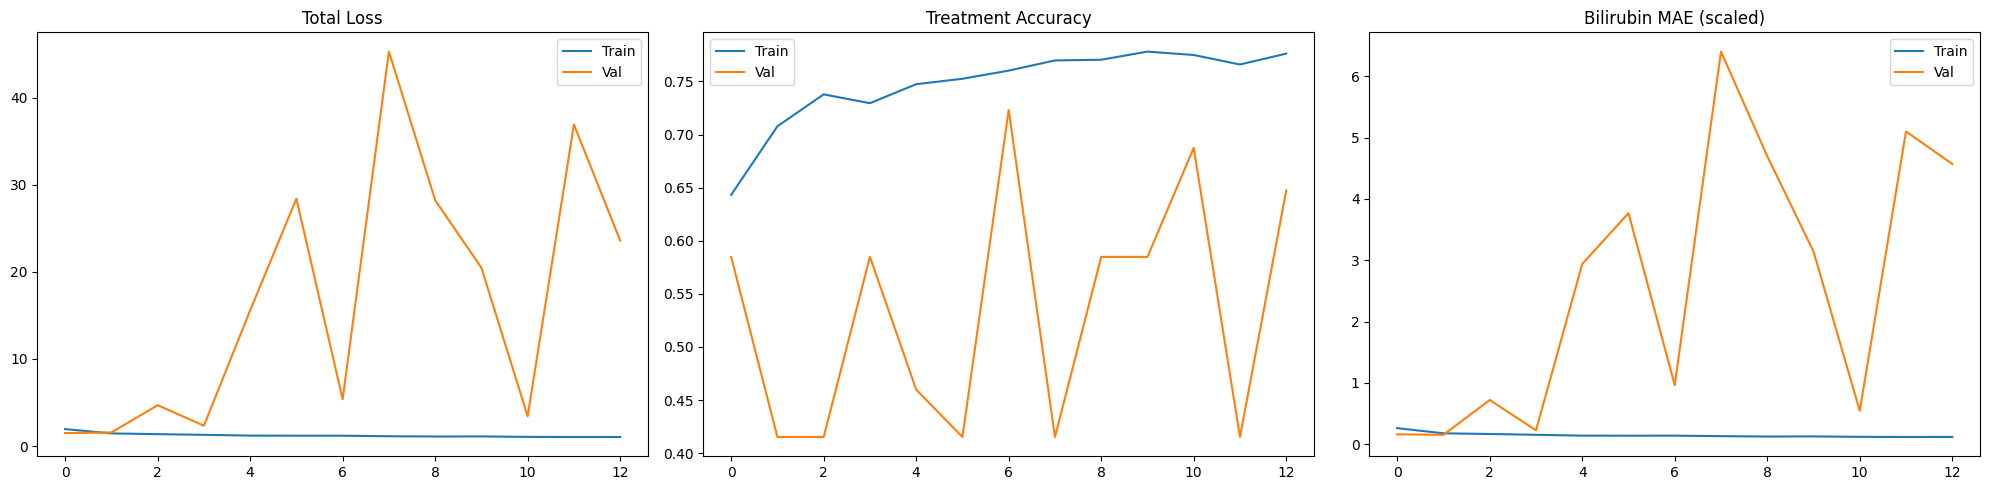

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Total loss
axes[0].plot(history.history['loss'], label='Train')
axes[0].plot(history.history['val_loss'], label='Val')
axes[0].set_title('Total Loss'); axes[0].legend()

# 2. Classification accuracy (find key dynamically)
acc_k  = [k for k in history.history if 'accuracy' in k and 'val' not in k][0]
vacc_k = [k for k in history.history if 'accuracy' in k and 'val' in k][0]
axes[1].plot(history.history[acc_k], label='Train')
axes[1].plot(history.history[vacc_k], label='Val')
axes[1].set_title('Treatment Accuracy'); axes[1].legend()

# 3. Regression MAE (find key dynamically)
mae_k  = [k for k in history.history if 'mae' in k and 'val' not in k][0]
vmae_k = [k for k in history.history if 'mae' in k and 'val' in k][0]
axes[2].plot(history.history[mae_k], label='Train')
axes[2].plot(history.history[vmae_k], label='Val')
axes[2].set_title('Bilirubin MAE (scaled)'); axes[2].legend()

plt.tight_layout()
plt.show()

## Cell 10: Final Evaluation on Unseen 20% Test Set
We un-scale the predictions back to real mg/dL and plot True (green) vs AI (orange).

In [18]:
# ── Predict on test set ──
preds = model.predict([X_rgb_test, X_hsv_test], verbose=0)
pred_treat = (preds[0].flatten() > 0.5).astype(int)
pred_bili_scaled = preds[1].flatten()

# Un-scale bilirubin predictions back to mg/dL
pred_bili_mgdl = bili_scaler.inverse_transform(pred_bili_scaled.reshape(-1, 1)).flatten()
true_bili_mgdl = bili_scaler.inverse_transform(yb_test.reshape(-1, 1)).flatten()

# ── Classification metrics ──
from sklearn.metrics import accuracy_score, classification_report
treat_acc = accuracy_score(yt_test, pred_treat)
print(f"═══ CLASSIFICATION (Treatment) ═══")
print(f"Accuracy: {treat_acc*100:.1f}%")
print(classification_report(yt_test, pred_treat, target_names=['No Treatment', 'Treatment']))

# ── Regression metrics ──
mae_mgdl = np.mean(np.abs(true_bili_mgdl - pred_bili_mgdl))
print(f"═══ REGRESSION (Bilirubin) ═══")
print(f"Mean Absolute Error: {mae_mgdl:.2f} mg/dL")
print(f"(On average, the AI is off by ±{mae_mgdl:.2f} mg/dL from the lab result)")

# ── Sample patients ──
print(f"\nSample predictions (first 10 patients):")
print(f"{'Patient':<10} {'True mg/dL':<12} {'AI mg/dL':<12} {'Error':<10} {'True Treat':<12} {'AI Treat':<10}")
print("─" * 66)
for i in range(min(10, len(true_bili_mgdl))):
    err = abs(true_bili_mgdl[i] - pred_bili_mgdl[i])
    print(f"{i+1:<10} {true_bili_mgdl[i]:<12.1f} {pred_bili_mgdl[i]:<12.1f} {err:<10.1f} {int(yt_test[i]):<12} {pred_treat[i]:<10}")

═══ CLASSIFICATION (Treatment) ═══
Accuracy: 58.2%
              precision    recall  f1-score   support

No Treatment       0.58      1.00      0.74       260
   Treatment       0.00      0.00      0.00       187

    accuracy                           0.58       447
   macro avg       0.29      0.50      0.37       447
weighted avg       0.34      0.58      0.43       447

═══ REGRESSION (Bilirubin) ═══
Mean Absolute Error: 4.51 mg/dL
(On average, the AI is off by ±4.51 mg/dL from the lab result)

Sample predictions (first 10 patients):
Patient    True mg/dL   AI mg/dL     Error      True Treat   AI Treat  
──────────────────────────────────────────────────────────────────
1          14.6         11.3         3.3        1            0         
2          8.5          11.0         2.5        0            0         
3          7.0          10.9         3.9        0            0         
4          2.9          10.8         7.9        0            0         
5          14.5         11.2

/Users/shubhbhateja/College/minor_project/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/shubhbhateja/College/minor_project/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/shubhbhateja/College/minor_project/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _

## Cell 11: Visual Regression Verification
Green line = True lab values. Orange crosses = AI predictions. Gray bars = error gap.

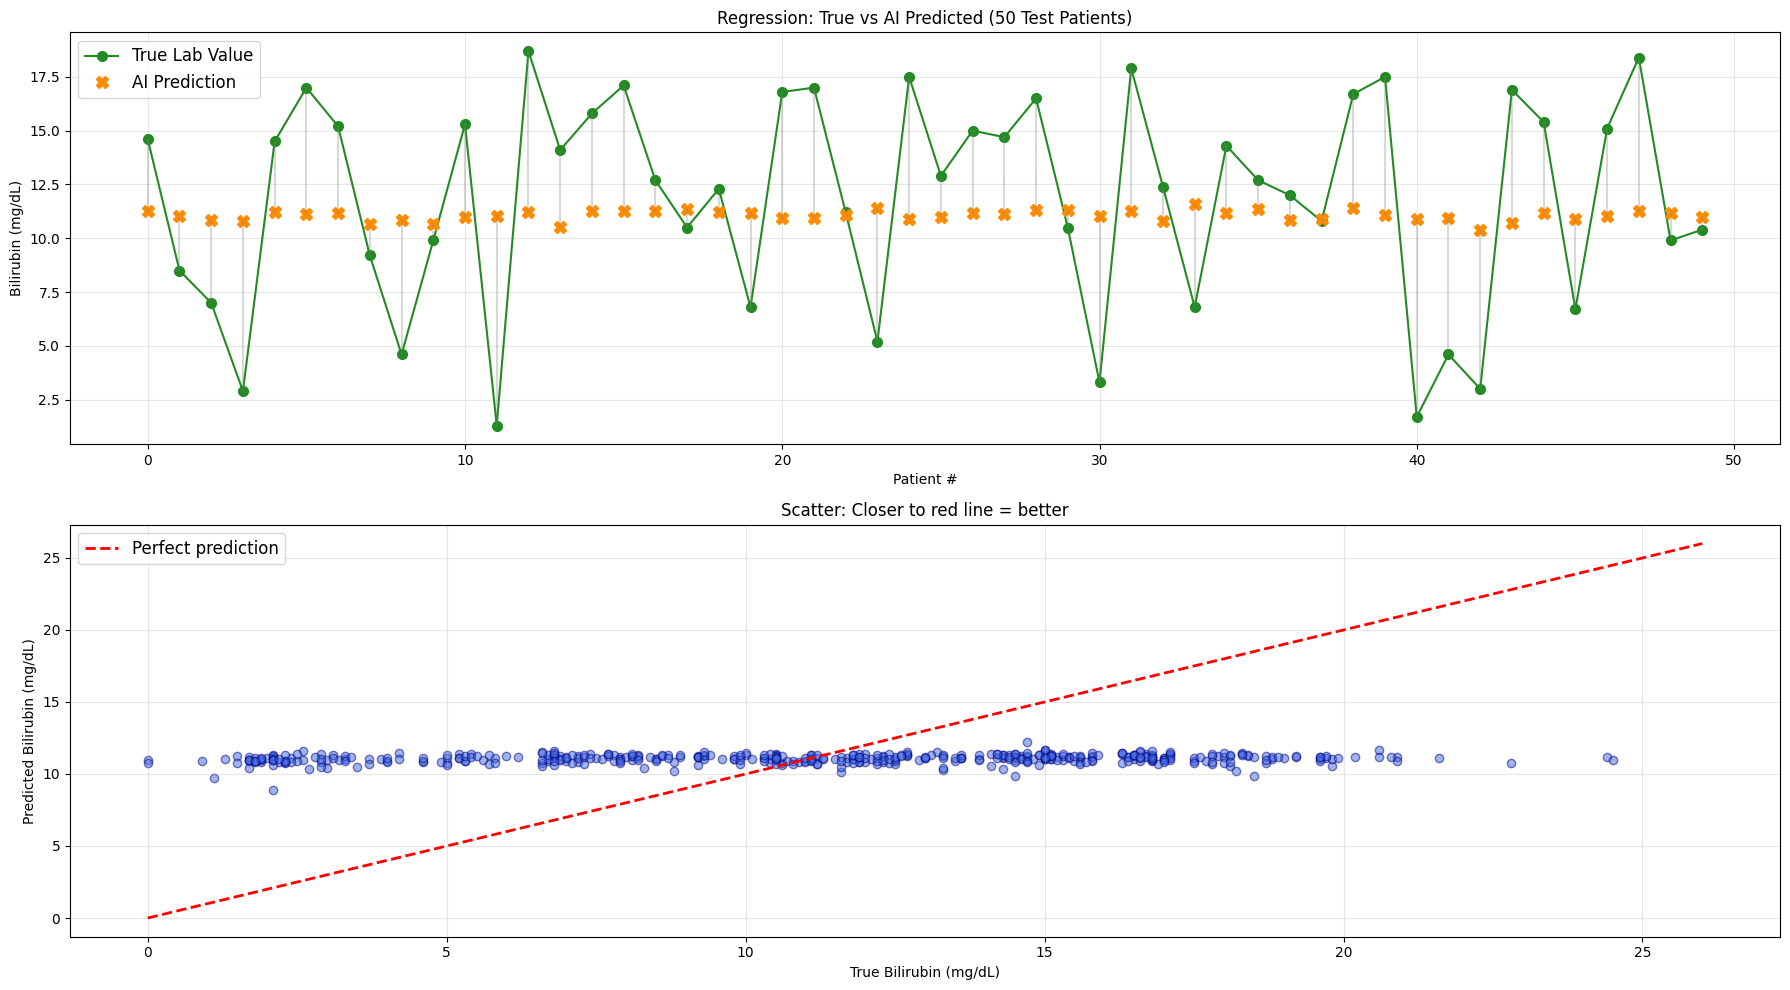

In [19]:
N = min(50, len(true_bili_mgdl))

fig, axes = plt.subplots(2, 1, figsize=(18, 10))

# ── Plot 1: Line chart (True vs Predicted) ──
axes[0].plot(range(N), true_bili_mgdl[:N], 'o-', color='forestgreen', markersize=7, label='True Lab Value')
axes[0].plot(range(N), pred_bili_mgdl[:N], 'X',  color='darkorange', markersize=9, label='AI Prediction')
for i in range(N):
    axes[0].plot([i, i], [true_bili_mgdl[i], pred_bili_mgdl[i]], color='gray', alpha=0.3)
axes[0].set_xlabel('Patient #')
axes[0].set_ylabel('Bilirubin (mg/dL)')
axes[0].set_title('Regression: True vs AI Predicted (50 Test Patients)')
axes[0].legend(fontsize=12)
axes[0].grid(True, alpha=0.3)

# ── Plot 2: Scatter (perfect = diagonal line) ──
axes[1].scatter(true_bili_mgdl, pred_bili_mgdl, alpha=0.5, color='royalblue', edgecolors='navy')
axes[1].plot([0, 26], [0, 26], 'r--', linewidth=2, label='Perfect prediction')
axes[1].set_xlabel('True Bilirubin (mg/dL)')
axes[1].set_ylabel('Predicted Bilirubin (mg/dL)')
axes[1].set_title('Scatter: Closer to red line = better')
axes[1].legend(fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()